In [1]:
import pandas as pd
import numpy as np 
import matplotlib.pyplot as plt
import seaborn as sns

In [2]:
import os
from io import BytesIO

import boto3
from botocore.client import Config
from dotenv import load_dotenv

load_dotenv()

BUCKET_NAME = os.environ["MINIO_BUCKET"]

s3_client = boto3.client(
    "s3",
    endpoint_url=os.environ["MINIO_ENDPOINT"],
    aws_access_key_id=os.environ["MINIO_ACCESS_KEY"],
    aws_secret_access_key=os.environ["MINIO_SECRET_KEY"],
    region_name="us-east-1",
    config=Config(signature_version="s3v4"),
)

In [3]:
def read_parquet_prefix(s3_client, bucket_name, prefix):
    """Read every Parquet object under a MinIO prefix."""
    paginator = s3_client.get_paginator("list_objects_v2")
    parquet_keys = []

    for page in paginator.paginate(Bucket=bucket_name, Prefix=prefix):
        for obj in page.get("Contents", []):
            key = obj["Key"]
            if key.endswith(".parquet"):
                parquet_keys.append(key)

    if not parquet_keys:
        raise FileNotFoundError(
            f"No Parquet files found under prefix: {prefix}"
        )

    dataframes = []
    for key in parquet_keys:
        response = s3_client.get_object(Bucket=bucket_name, Key=key)
        dataframe = pd.read_parquet(
            BytesIO(response["Body"].read()),
            engine="fastparquet",
        )
        dataframes.append(dataframe)
        print(f"Loaded: {key}")
        print(f"Shape: {dataframe.shape}")

    return pd.concat(dataframes, ignore_index=True)


def read_parquet_object(s3_client, bucket_name, object_key):
    response = s3_client.get_object(Bucket=bucket_name, Key=object_key)
    return pd.read_parquet(
        BytesIO(response["Body"].read()),
        engine="fastparquet",
    )

In [4]:
metadata_df = read_parquet_prefix(
    s3_client,
    BUCKET_NAME,
    "metadata/etl_metadata/"
)

required_gold_datasets = {"train_features", "test_features"}
successful_gold_metadata = metadata_df[
    (metadata_df["layer"] == "gold")
    & (metadata_df["status"] == "success")
    & metadata_df["dataset_name"].isin(required_gold_datasets)
]

datasets_by_run = successful_gold_metadata.groupby("run_id")["dataset_name"].apply(set)
valid_gold_run_ids = sorted(
    run_id
    for run_id, datasets in datasets_by_run.items()
    if required_gold_datasets.issubset(datasets)
)

if not valid_gold_run_ids:
    raise FileNotFoundError(
        "No successful Gold run contains train_features and test_features data."
    )

pipeline_run_id = valid_gold_run_ids[-1]
selected_gold_metadata = successful_gold_metadata[
    successful_gold_metadata["run_id"] == pipeline_run_id
]
pipeline_load_date = selected_gold_metadata["load_date"].iloc[0]
metadata_key = (
    f"metadata/etl_metadata/load_date={pipeline_load_date}/"
    f"run_id={pipeline_run_id}/manifest.parquet"
)

def gold_object_key(dataset_name):
    matches = selected_gold_metadata[
        selected_gold_metadata["dataset_name"] == dataset_name
    ]
    if len(matches) != 1:
        raise ValueError(f"Expected one Gold object for {dataset_name}.")
    return matches.iloc[0]["object_key"]

train_features = read_parquet_object(
    s3_client, BUCKET_NAME, gold_object_key("train_features")
)
test_features = read_parquet_object(
    s3_client, BUCKET_NAME, gold_object_key("test_features")
)

print(f"Selected Silver run: {pipeline_run_id}")

Loaded: metadata/etl_metadata/load_date=2026-09-02/run_id=20260902T120041719003Z/manifest.parquet
Shape: (9, 8)
Selected Silver run: 20260902T120041719003Z


In [5]:
pd.set_option('display.max_columns', None)

In [6]:
modeling_train_df = train_features[train_features["time_in_cycles"]>19].copy()

In [7]:
len(modeling_train_df)

18731

In [8]:
modeling_train_df.head()

,unit_number,time_in_cycles,operational_setting_1,operational_setting_2,operational_setting_3,current_sensor_measurement_1,current_sensor_measurement_2,current_sensor_measurement_3,current_sensor_measurement_4,current_sensor_measurement_5,current_sensor_measurement_6,current_sensor_measurement_7,current_sensor_measurement_8,current_sensor_measurement_9,current_sensor_measurement_10,current_sensor_measurement_11,current_sensor_measurement_12,current_sensor_measurement_13,current_sensor_measurement_14,current_sensor_measurement_15,current_sensor_measurement_16,current_sensor_measurement_17,current_sensor_measurement_18,current_sensor_measurement_19,current_sensor_measurement_20,current_sensor_measurement_21,sensor_measurement_1_mean_20,sensor_measurement_2_mean_20,sensor_measurement_3_mean_20,sensor_measurement_4_mean_20,sensor_measurement_5_mean_20,sensor_measurement_6_mean_20,sensor_measurement_7_mean_20,sensor_measurement_8_mean_20,sensor_measurement_9_mean_20,sensor_measurement_10_mean_20,sensor_measurement_11_mean_20,sensor_measurement_12_mean_20,sensor_measurement_13_mean_20,sensor_measurement_14_mean_20,sensor_measurement_15_mean_20,sensor_measurement_16_mean_20,sensor_measurement_17_mean_20,sensor_measurement_18_mean_20,sensor_measurement_19_mean_20,sensor_measurement_20_mean_20,sensor_measurement_21_mean_20,sensor_measurement_1_std_20,sensor_measurement_2_std_20,sensor_measurement_3_std_20,sensor_measurement_4_std_20,sensor_measurement_5_std_20,sensor_measurement_6_std_20,sensor_measurement_7_std_20,sensor_measurement_8_std_20,sensor_measurement_9_std_20,sensor_measurement_10_std_20,sensor_measurement_11_std_20,sensor_measurement_12_std_20,sensor_measurement_13_std_20,sensor_measurement_14_std_20,sensor_measurement_15_std_20,sensor_measurement_16_std_20,sensor_measurement_17_std_20,sensor_measurement_18_std_20,sensor_measurement_19_std_20,sensor_measurement_20_std_20,sensor_measurement_21_std_20,sensor_measurement_1_min_20,sensor_measurement_2_min_20,sensor_measurement_3_min_20,sensor_measurement_4_min_20,sensor_measurement_5_min_20,sensor_measurement_6_min_20,sensor_measurement_7_min_20,sensor_measurement_8_min_20,sensor_measurement_9_min_20,sensor_measurement_10_min_20,sensor_measurement_11_min_20,sensor_measurement_12_min_20,sensor_measurement_13_min_20,sensor_measurement_14_min_20,sensor_measurement_15_min_20,sensor_measurement_16_min_20,sensor_measurement_17_min_20,sensor_measurement_18_min_20,sensor_measurement_19_min_20,sensor_measurement_20_min_20,sensor_measurement_21_min_20,sensor_measurement_1_max_20,sensor_measurement_2_max_20,sensor_measurement_3_max_20,sensor_measurement_4_max_20,sensor_measurement_5_max_20,sensor_measurement_6_max_20,sensor_measurement_7_max_20,sensor_measurement_8_max_20,sensor_measurement_9_max_20,sensor_measurement_10_max_20,sensor_measurement_11_max_20,sensor_measurement_12_max_20,sensor_measurement_13_max_20,sensor_measurement_14_max_20,sensor_measurement_15_max_20,sensor_measurement_16_max_20,sensor_measurement_17_max_20,sensor_measurement_18_max_20,sensor_measurement_19_max_20,sensor_measurement_20_max_20,sensor_measurement_21_max_20,sensor_measurement_1_difference,sensor_measurement_2_difference,sensor_measurement_3_difference,sensor_measurement_4_difference,sensor_measurement_5_difference,sensor_measurement_6_difference,sensor_measurement_7_difference,sensor_measurement_8_difference,sensor_measurement_9_difference,sensor_measurement_10_difference,sensor_measurement_11_difference,sensor_measurement_12_difference,sensor_measurement_13_difference,sensor_measurement_14_difference,sensor_measurement_15_difference,sensor_measurement_16_difference,sensor_measurement_17_difference,sensor_measurement_18_difference,sensor_measurement_19_difference,sensor_measurement_20_difference,sensor_measurement_21_difference,sensor_measurement_1_%change,sensor_measurement_2_%change,sensor_measurement_3_%change,sensor_measurement_4_%change,sensor_measurement_5_%change,sensor_measurement_6_%change,sensor

In [9]:
engine_ids = [int(x) for x in modeling_train_df["unit_number"].unique()]

In [10]:
rng = np.random.default_rng(seed = 42)
ids_shuffled = rng.permutation(engine_ids)

In [11]:
train_engine_ids = ids_shuffled[:int(0.8 *len(ids_shuffled))]
validation_engine_ids = ids_shuffled[int(0.8 *len(ids_shuffled)):]

In [12]:
training_rows = modeling_train_df[modeling_train_df["unit_number"].isin(train_engine_ids)]
validation_rows = modeling_train_df[modeling_train_df["unit_number"].isin(validation_engine_ids)]

In [13]:
if not set(train_engine_ids).isdisjoint(validation_engine_ids):
    raise ValueError (f"Engine existing in both train and test datasets")

In [14]:
train_groups = training_rows["unit_number"]
X_train = training_rows.drop(columns=["unit_number","remaining_useful_life"])
y_train = training_rows["remaining_useful_life"]
test_groups = validation_rows["unit_number"]
X_test = validation_rows.drop(columns=["unit_number","remaining_useful_life"])
y_test = validation_rows["remaining_useful_life"]

In [15]:
train_constant_columns = [
    column for column in X_train.columns
    if X_train[column].nunique(dropna=False) == 1
]
X_train = X_train.drop(columns=train_constant_columns)
X_test = X_test.drop(columns=train_constant_columns)

In [16]:
from sklearn.metrics import mean_squared_error,mean_absolute_error,r2_score

In [17]:
mean_rul = y_train.mean()
mean_validation_predictions = np.full(
    len(y_test),
    mean_rul,
)
mean_baseline_mae = mean_absolute_error(
    y_test,
    mean_validation_predictions,
)

mean_baseline_rmse = mean_squared_error(
    y_test,
    mean_validation_predictions,
) ** 0.5

mean_baseline_r2 = r2_score(
    y_test,
    mean_validation_predictions,
)
mean_validation_predictions = pd.Series(mean_validation_predictions,index=y_test.index)
mean_prediction_error = y_test - mean_validation_predictions
print("MAE for mean baseline model :",mean_baseline_mae)
print("RMSE for mean baseline model :",mean_baseline_rmse)
print("R2 for mean baseline model :",mean_baseline_r2)
if mean_prediction_error.mean() > 0:
    print("mean baseline model is  pessimistic, predicts failure early")
else: 
    print("mean baseline model is optimistic, predicts failure late")

MAE for mean baseline model : 52.27230702650257
RMSE for mean baseline model : 63.15659578065061
R2 for mean baseline model : -0.0002068681218732049
mean baseline model is optimistic, predicts failure late


In [18]:
def evaluation(model_name,y_test,predictions,validation_rows):
    model_mae = mean_absolute_error(
        y_test,
        predictions,
    )

    model_rmse = mean_squared_error(
        y_test,
        predictions,
    ) ** 0.5

    model_r2 = r2_score(
        y_test,
        predictions,
    )
    model_predictions = pd.Series(predictions,index=y_test.index)
    model_error = y_test - model_predictions
    print(f"MAE for {model_name} model :",model_mae)
    print(f"RMSE for {model_name} model :",model_rmse)
    print(f"R2 for {model_name} model :",model_r2)
    if model_error.mean() > 0:
        print(f"{model_name} is pessimistic, predicts failure earlier")
    else:
        print(f"{model_name} is too optimistic, predicts failure late")

    print(f"\n{model_name}")
    print("Number of actual critical observations (RUL<=10) :",len(y_test[y_test<=10]))
    print("Number of predicted critical observations (RUL<=10) :",len(model_predictions[model_predictions<=10]))

    print("\nNumber of actual warning observations (10 < RUL <= 30) :",len(y_test[(y_test > 10) & (y_test <= 30)]))
    print("Number of predicted warning observations (10 < RUL <= 30) :",len(model_predictions[(model_predictions > 10) & (model_predictions <= 30)]))

    print("\nNumber of actual Healthy observations (RUL>30) :",len(y_test[y_test>30]))
    print("Number of predicted Healthy observations (RUL>30) :",len(model_predictions[model_predictions>30]))

    model_comparison = pd.concat([y_test,model_predictions],axis=1)
    model_comparison = model_comparison.rename(columns={0:"predicted_rul"})

    critical_mae = mean_absolute_error(
        model_comparison[model_comparison["remaining_useful_life"]<=10]["remaining_useful_life"],
        model_comparison[model_comparison["remaining_useful_life"]<=10]["predicted_rul"],
    )

    warning_mae = mean_absolute_error(
        model_comparison[(model_comparison["remaining_useful_life"] > 10) & (model_comparison["remaining_useful_life"] <= 30)]["remaining_useful_life"],
        model_comparison[(model_comparison["remaining_useful_life"] > 10) & (model_comparison["remaining_useful_life"] <= 30)]["predicted_rul"],
    )

    healthy_mae = mean_absolute_error(
        model_comparison[model_comparison["remaining_useful_life"]>30]["remaining_useful_life"],
        model_comparison[model_comparison["remaining_useful_life"]>30]["predicted_rul"],
    )

    print("\nMAE for critical observations :",critical_mae)
    print("MAE for warning observations :",warning_mae)
    print("MAE for healthy observations :",healthy_mae)

    critical_rmse = mean_squared_error(
        model_comparison[model_comparison["remaining_useful_life"]<=10]["remaining_useful_life"],
        model_comparison[model_comparison["remaining_useful_life"]<=10]["predicted_rul"],
    ) ** 0.5

    warning_rmse = mean_squared_error(
        model_comparison[(model_comparison["remaining_useful_life"] > 10) & (model_comparison["remaining_useful_life"] <= 30)]["remaining_useful_life"],
        model_comparison[(model_comparison["remaining_useful_life"] > 10) & (model_comparison["remaining_useful_life"] <= 30)]["predicted_rul"],
    ) ** 0.5

    healthy_rmse = mean_squared_error(
        model_comparison[model_comparison["remaining_useful_life"]>30]["remaining_useful_life"],
        model_comparison[model_comparison["remaining_useful_life"]>30]["predicted_rul"],
    ) ** 0.5

    print("RMSE for critical observations :",critical_rmse)
    print("RMSE for warning observations :",warning_rmse)
    print("RMSE for healthy observations :",healthy_rmse)

    critical_error_mean = (model_comparison[model_comparison["remaining_useful_life"]<=10]["remaining_useful_life"] - model_comparison[model_comparison["remaining_useful_life"]<=10]["predicted_rul"]).mean()
    warning_error_mean = (model_comparison[(model_comparison["remaining_useful_life"] > 10) & (model_comparison["remaining_useful_life"] <= 30)]["remaining_useful_life"] - model_comparison[(model_comparison["remaining_useful_life"] > 10) & (model_comparison["remaining_useful_life"] <= 30)]["predicted_rul"]).mean()
    healthy_error_mean = (model_comparison[model_comparison["remaining_useful_life"]>30]["remaining_useful_life"] - model_comparison[model_comparison["remaining_useful_life"]>30]["predicted_rul"]).mean()

    print("\nCritical mean signed error :",critical_error_mean)
    print("Warning mean signed error :",warning_error_mean)
    print("Healthy mean signed error :",healthy_error_mean)

    predicted_validation_rows = validation_rows.copy()
    predicted_validation_rows["predicted_remaining_useful_life"] = model_predictions
    predicted_validation_rows["rul_difference"] = predicted_validation_rows["remaining_useful_life"] - predicted_validation_rows["predicted_remaining_useful_life"]
    predicted_validation_rows["rul_difference"] = predicted_validation_rows["rul_difference"].apply(lambda x: -x if x<0 else x)
    mae_by_engine = predicted_validation_rows.groupby("unit_number")["rul_difference"].mean()
    max_absolute_error = mae_by_engine.max()

    predicted_validation_rows["rul_difference_2"] = predicted_validation_rows["remaining_useful_life"] - predicted_validation_rows["predicted_remaining_useful_life"]
    predicted_validation_rows["rul_difference_2"] = predicted_validation_rows["rul_difference_2"] * predicted_validation_rows["rul_difference_2"]
    rmse_by_engine = predicted_validation_rows.groupby("unit_number")["rul_difference_2"].mean()
    rmse_by_engine = np.sqrt(rmse_by_engine)

    predicted_validation_rows["rul_difference_3"] = predicted_validation_rows["remaining_useful_life"] - predicted_validation_rows["predicted_remaining_useful_life"]
    mean_error_by_engine = predicted_validation_rows.groupby("unit_number")["rul_difference_3"].mean()

    print("\nMAE by engine :\n",mae_by_engine)
    print("\nRMSE by engine :\n",rmse_by_engine)
    print("\nMean signed error by engine :\n",mean_error_by_engine)
    print("\nMaximum engine MAE :",max_absolute_error)

    predicted_validation_rows = predicted_validation_rows.sort_values(["unit_number", "time_in_cycles"])
    prediction_change = predicted_validation_rows.groupby("unit_number")["predicted_remaining_useful_life"].diff()
    prediction_change = prediction_change.dropna()
    percentage_increasing = (prediction_change.gt(0).mean() * 100)
    print(f"\nMean signed prediction change between consecutive cycles : {prediction_change.mean():.2f}")
    print(f"Mean absolute prediction change between consecutive cycles : {prediction_change.abs().mean():.2f}")
    print(f"Percentage of rul that increase after a specific cycle : {percentage_increasing:.2f}%")
    print(f"Largest prediction jump : {prediction_change.abs().max():.2f}")

    engines_to_plot = {}
    mae_by_engine = mae_by_engine.sort_values()
    worst_engine = mae_by_engine.index[len(mae_by_engine)-1]
    engines_to_plot.update({"Worst Engine":int(worst_engine)})
    best_engine = mae_by_engine.index[0]
    engines_to_plot.update({"Best Engine":int(best_engine)})
    average_engine = mae_by_engine.index[int(len(mae_by_engine)/2)]
    engines_to_plot.update({"Average Engine":int(average_engine)})
    prediction_change_by_engine = (
        predicted_validation_rows
        .sort_values(["unit_number", "time_in_cycles"])
        .groupby("unit_number")["predicted_remaining_useful_life"]
        .diff()
    )

    stability_by_engine = (
        prediction_change_by_engine
        .abs()
        .groupby(predicted_validation_rows["unit_number"])
        .mean()
    )

    unstable_engine = stability_by_engine.idxmax()
    engines_to_plot.update({"Unstable Engine":int(unstable_engine)})
    print("\nEngines selected for prediction plots :",engines_to_plot)

    for engine_name,engine_id in engines_to_plot.items():
        plt.figure(figsize=(12, 5))

        plot_data = predicted_validation_rows[
            predicted_validation_rows["unit_number"] == engine_id
        ]

        sns.lineplot(
            data=plot_data,
            x="time_in_cycles",
            y="remaining_useful_life",
            label="Actual RUL",
        )
        sns.lineplot(
            data=plot_data,
            x="time_in_cycles",
            y="predicted_remaining_useful_life",
            label="Predicted RUL",
        )

        plt.title(f"{model_name} prediction curves for {engine_name}")
        plt.xlabel("Operating cycle")
        plt.ylabel("RUL")
        plt.grid(True)
        plt.show()

    missed_critical_observations = predicted_validation_rows[(predicted_validation_rows["remaining_useful_life"]<=10)&(predicted_validation_rows["predicted_remaining_useful_life"]>10)]
    print("\nNumber of missed critical observations :",len(missed_critical_observations))
    print(f"Percentage of critical observations missed : {(len(missed_critical_observations)/len(predicted_validation_rows[predicted_validation_rows['remaining_useful_life']<=10]))*100:.2f}%")
    print(f"The {missed_critical_observations['unit_number'].nunique()} affected engines and their number of misses :")
    print(missed_critical_observations["unit_number"].value_counts())

    false_alarms = predicted_validation_rows[(predicted_validation_rows["remaining_useful_life"]>30)&(predicted_validation_rows["predicted_remaining_useful_life"]<=30)]
    print("\nNumber of false alarms :",len(false_alarms))
    print(f"Percentage of FALSE alarms : {(len(false_alarms)/len(predicted_validation_rows[predicted_validation_rows['remaining_useful_life']>30]))*100:.2f}%")

    warning_cycles = predicted_validation_rows[(predicted_validation_rows["remaining_useful_life"]<=30)&(predicted_validation_rows["remaining_useful_life"]>10)][["unit_number","time_in_cycles","remaining_useful_life","predicted_remaining_useful_life"]].copy()
    warning_cycles["received_warning"] = warning_cycles["predicted_remaining_useful_life"].apply(lambda x: 1 if x<=30 else 0)
    number_of_warning_per_engine = warning_cycles.groupby("unit_number")["received_warning"].sum()

    print(f"\nPercentage of failures identified early : {(len(number_of_warning_per_engine[number_of_warning_per_engine>0])/len(number_of_warning_per_engine))*100:.2f}%")
    print("Full list of each engine and number of warnings received :\n",number_of_warning_per_engine)

    temp = predicted_validation_rows[["unit_number","time_in_cycles","remaining_useful_life","predicted_remaining_useful_life"]].copy()
    temp["received_warning"] = temp["predicted_remaining_useful_life"].apply(lambda x: 1 if x<=30 else 0)
    first_warning = (
        temp[temp["received_warning"] == 1]
        .sort_values(["unit_number", "time_in_cycles"])
        .groupby("unit_number")
        .first()
    )
    print(f"\nAverage warning lead time : {first_warning['remaining_useful_life'].mean():.2f}")
    print(f"Number of Premature alerts : {len(first_warning[first_warning['remaining_useful_life']>30])}")
    print(f"Number of Timely alerts : {len(first_warning[(first_warning['remaining_useful_life']<=30)&(first_warning['remaining_useful_life']>10)])}")
    print(f"Number of Late alerts : {len(first_warning[first_warning['remaining_useful_life']<=10])}")
    number_of_engines_without_alert = (
        validation_rows["unit_number"].nunique()
        - first_warning.index.nunique()
    )
    print("Number of engines which received no warning:",number_of_engines_without_alert)


# Linear Regression

In [19]:
from sklearn.linear_model import LinearRegression
from sklearn.preprocessing import StandardScaler

scaler = StandardScaler()
X_train_scaled = scaler.fit_transform(X_train)
X_test_scaled = scaler.transform(X_test)

Lin_Reg = LinearRegression(n_jobs=4)
Lin_Reg.fit(X_train_scaled,y_train)
Lin_Reg_validation_predictions = Lin_Reg.predict(X_test_scaled)


MAE for Linear Regression model : 26.975360864588414
RMSE for Linear Regression model : 36.325707664853546
R2 for Linear Regression model : 0.6691123380062189
Linear Regression is pessimistic, predicts failure earlier

Linear Regression
Number of actual critical observations (RUL<=10) : 220
Number of predicted critical observations (RUL<=10) : 306

Number of actual warning observations (10 < RUL <= 30) : 400
Number of predicted warning observations (10 < RUL <= 30) : 189

Number of actual Healthy observations (RUL>30) : 3104
Number of predicted Healthy observations (RUL>30) : 3229

MAE for critical observations : 20.999240979134452
MAE for warning observations : 17.935263835340397
MAE for healthy observations : 28.563887020032706
RMSE for critical observations : 26.68617497734023
RMSE for warning observations : 21.9022996257808
RMSE for healthy observations : 38.35147029508356

Critical mean signed error : 17.66671328706952
Warning mean signed error : -5.084658840012205
Healthy mean si

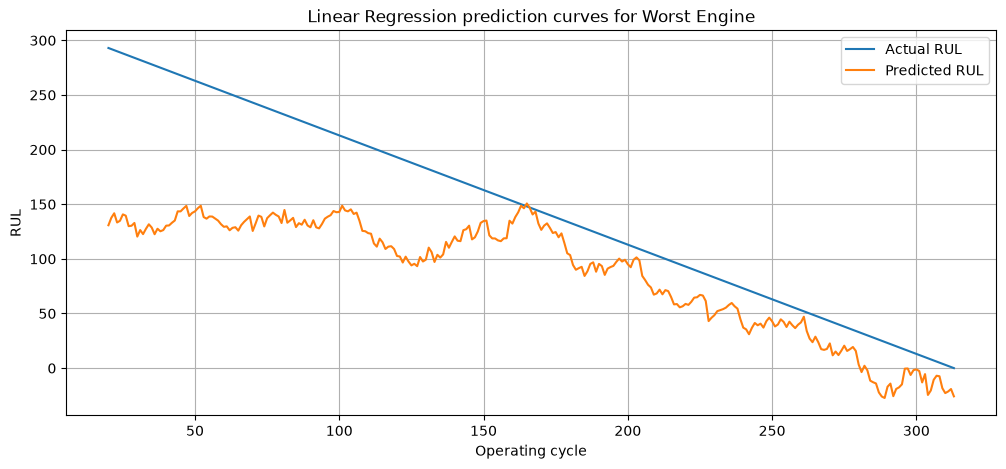

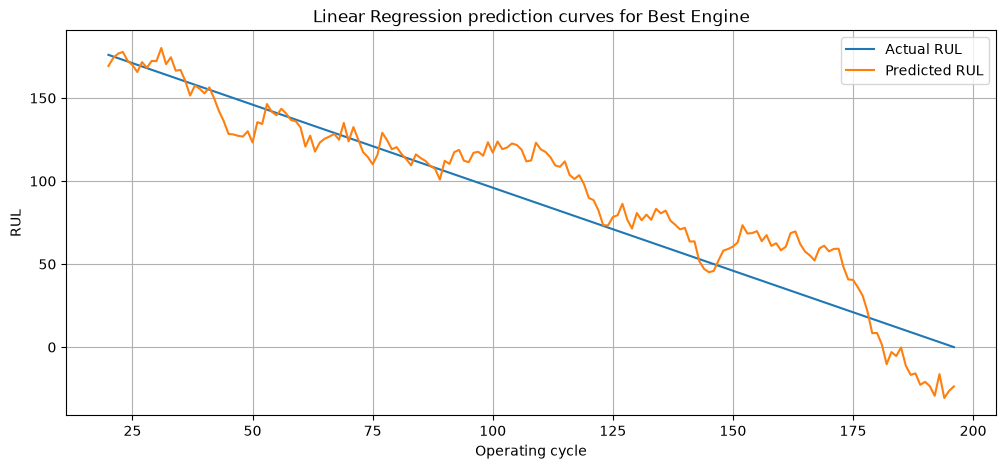

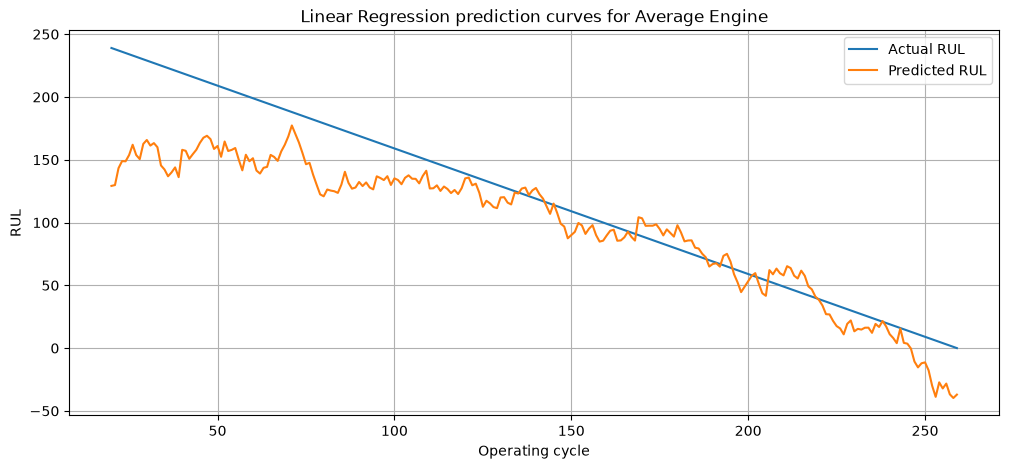

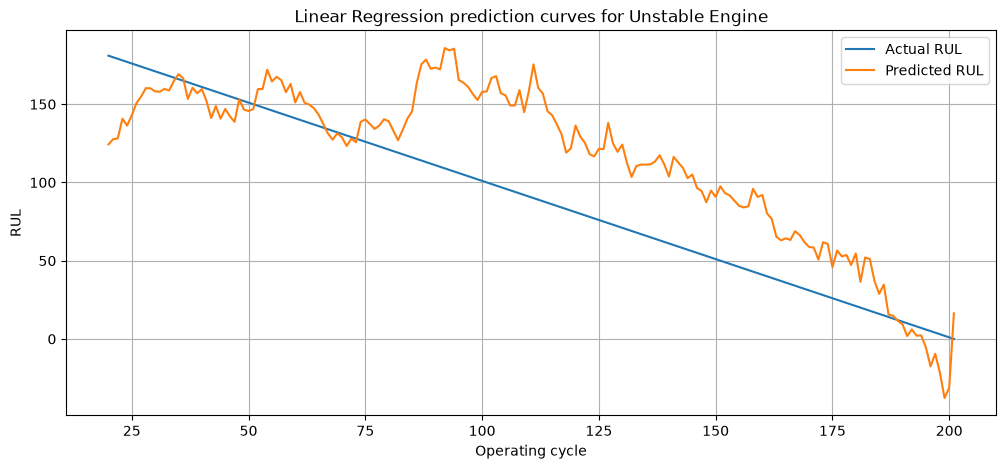


Number of missed critical observations : 29
Percentage of critical observations missed : 13.18%
The 9 affected engines and their number of misses :
unit_number
91    8
20    6
36    5
14    3
66    3
9     1
12    1
23    1
48    1
Name: count, dtype: int64

Number of false alarms : 56
Percentage of FALSE alarms : 1.80%

Percentage of failures identified early : 90.00%
Full list of each engine and number of warnings received :
 unit_number
7     20
9      5
12     0
13     8
14     8
15    18
20    13
23     8
36     5
37    11
42     8
48     9
50     4
54    20
65     8
66    17
67    20
78    20
86    19
91     0
Name: received_warning, dtype: int64

Average warning lead time : 25.65
Number of Premature alerts : 6
Number of Timely alerts : 12
Number of Late alerts : 2
Number of engines which received no warning: 0


In [20]:
evaluation("Linear Regression",y_test,Lin_Reg_validation_predictions,validation_rows)


# Random Forest 

In [21]:
from sklearn.ensemble import RandomForestRegressor

Ran_Forest = RandomForestRegressor(n_jobs=10,random_state=42)
Ran_Forest.fit(X_train,y_train)
Ran_Forest_validation_predictions = Ran_Forest.predict(X_test)


MAE for Random Forest model : 26.280738453276047
RMSE for Random Forest model : 38.858964457592464
R2 for Random Forest model : 0.6213527103303564
Random Forest is pessimistic, predicts failure earlier

Random Forest
Number of actual critical observations (RUL<=10) : 220
Number of predicted critical observations (RUL<=10) : 187

Number of actual warning observations (10 < RUL <= 30) : 400
Number of predicted warning observations (10 < RUL <= 30) : 386

Number of actual Healthy observations (RUL>30) : 3104
Number of predicted Healthy observations (RUL>30) : 3151

MAE for critical observations : 3.0968181818181817
MAE for warning observations : 5.906375000000001
MAE for healthy observations : 30.549490979381446
RMSE for critical observations : 3.704932584345558
RMSE for warning observations : 7.921252852295525
RMSE for healthy observations : 42.45674293388653

Critical mean signed error : -2.364181818181818
Warning mean signed error : -3.412825
Healthy mean signed error : 5.7846842783505

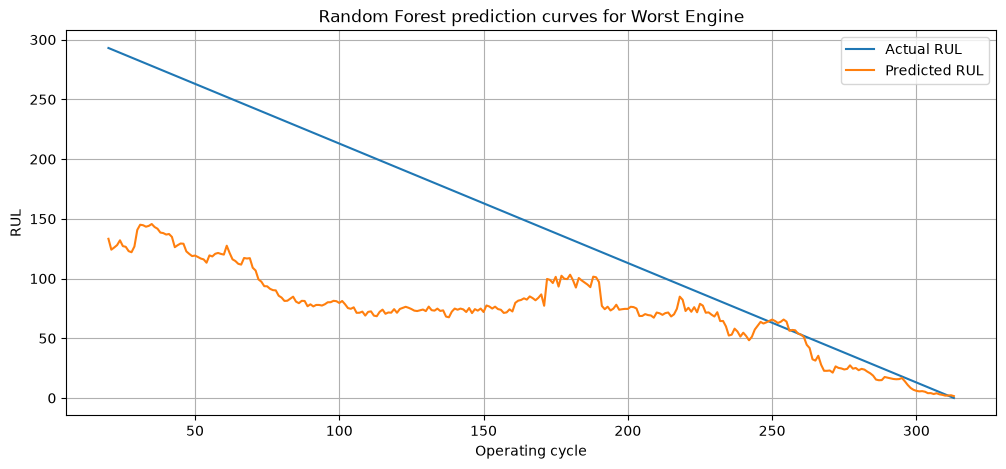

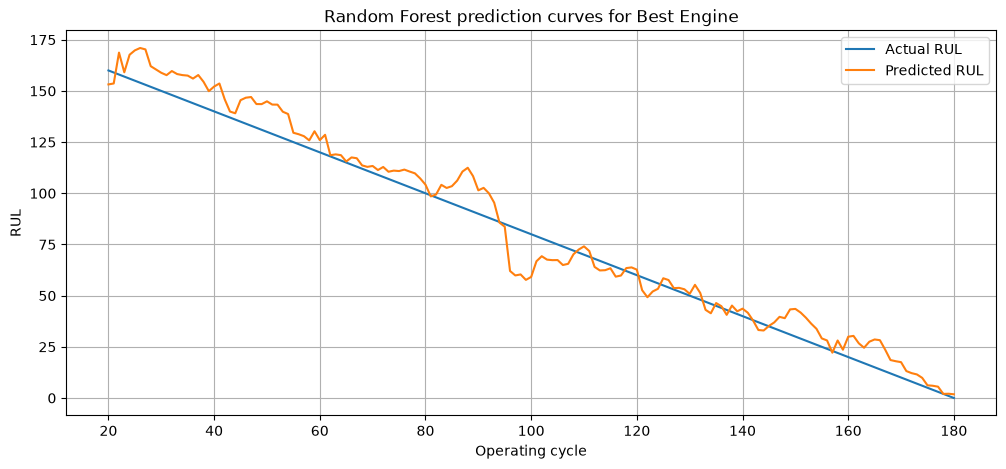

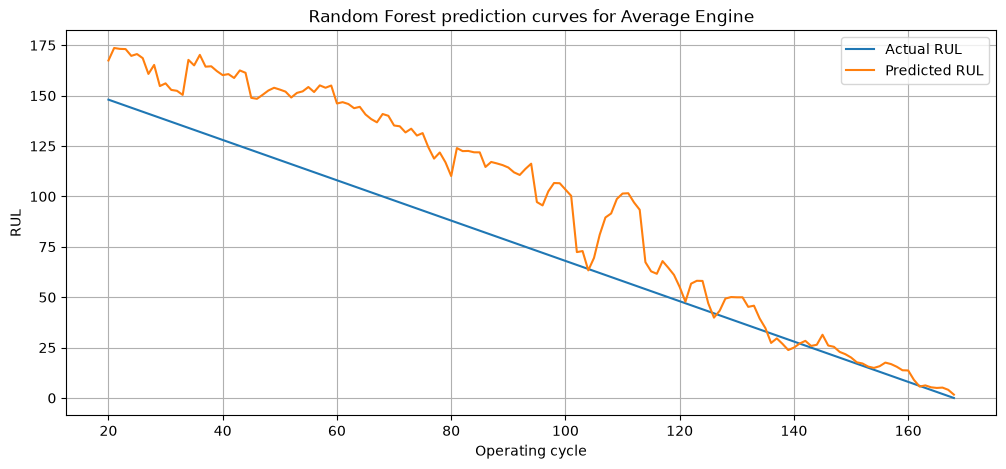

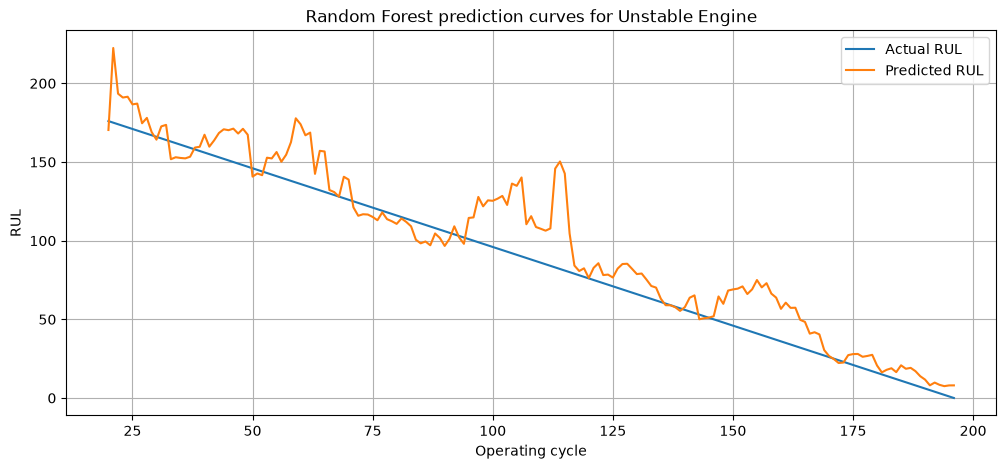


Number of missed critical observations : 54
Percentage of critical observations missed : 24.55%
The 16 affected engines and their number of misses :
unit_number
37    6
15    5
42    5
48    5
13    4
14    4
36    4
54    4
65    4
23    3
78    3
9     2
12    2
20    1
50    1
91    1
Name: count, dtype: int64

Number of false alarms : 44
Percentage of FALSE alarms : 1.42%

Percentage of failures identified early : 100.00%
Full list of each engine and number of warnings received :
 unit_number
7     15
9     12
12    10
13    14
14    14
15    12
20    20
23    19
36    17
37    14
42    16
48    14
50    17
54    15
65     9
66    20
67    20
78    14
86    20
91    17
Name: received_warning, dtype: int64

Average warning lead time : 28.20
Number of Premature alerts : 6
Number of Timely alerts : 14
Number of Late alerts : 0
Number of engines which received no warning: 0


In [22]:
evaluation("Random Forest",y_test,Ran_Forest_validation_predictions,validation_rows)


# XGBOOST 

In [23]:
from xgboost import XGBRegressor

xgb = XGBRegressor(n_jobs=11,random_state=41)
xgb.fit(X_train,y_train)
xgb_validation_predictions = xgb.predict(X_test)


MAE for XGBoost model : 26.714122772216797
RMSE for XGBoost model : 39.18028180631011
R2 for XGBoost model : 0.6150648593902588
XGBoost is pessimistic, predicts failure earlier

XGBoost
Number of actual critical observations (RUL<=10) : 220
Number of predicted critical observations (RUL<=10) : 195

Number of actual warning observations (10 < RUL <= 30) : 400
Number of predicted warning observations (10 < RUL <= 30) : 366

Number of actual Healthy observations (RUL>30) : 3104
Number of predicted Healthy observations (RUL>30) : 3163

MAE for critical observations : 3.0793919563293457
MAE for warning observations : 6.806959629058838
MAE for healthy observations : 30.954620361328125
RMSE for critical observations : 3.878809871033253
RMSE for warning observations : 10.017403907324516
RMSE for healthy observations : 42.75184315059922

Critical mean signed error : -1.8284039415757765
Warning mean signed error : -3.4977231431007385
Healthy mean signed error : 3.888552101002526

MAE by engine :

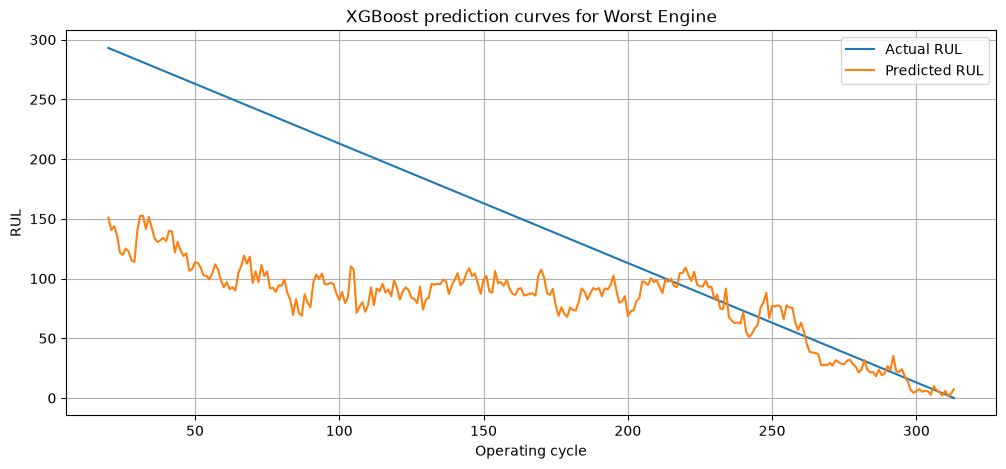

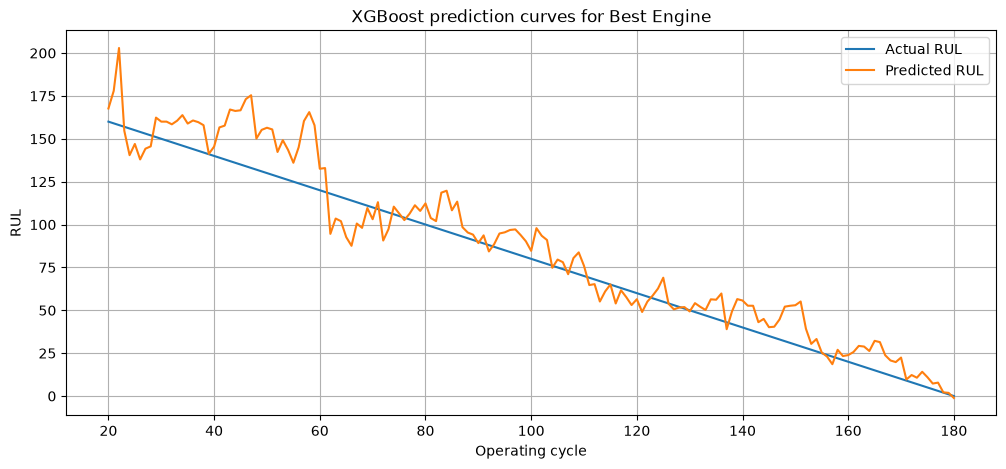

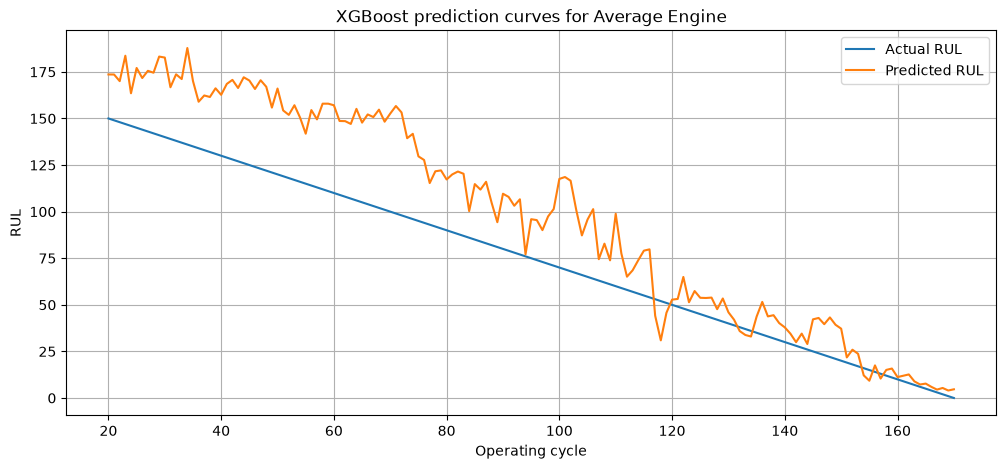

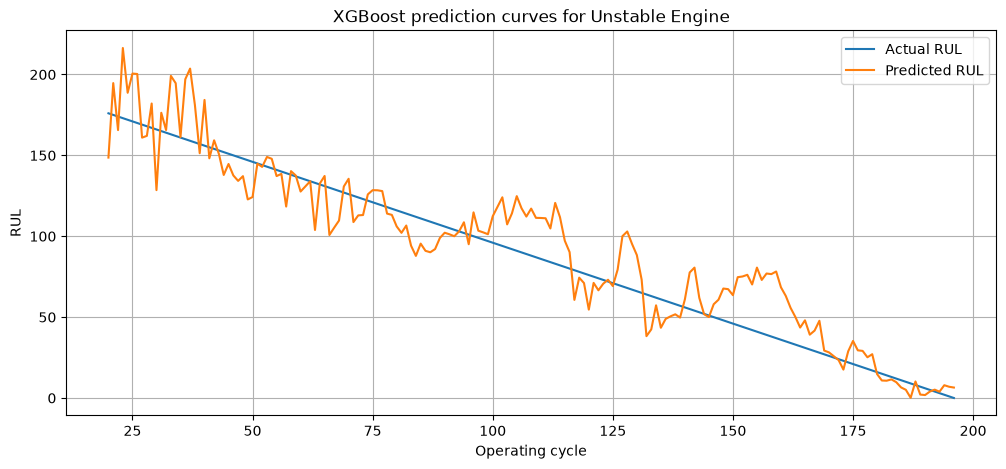


Number of missed critical observations : 52
Percentage of critical observations missed : 23.64%
The 17 affected engines and their number of misses :
unit_number
20    6
36    6
14    5
15    5
54    5
13    4
78    4
12    3
23    2
48    2
65    2
86    2
91    2
9     1
37    1
42    1
50    1
Name: count, dtype: int64

Number of false alarms : 39
Percentage of FALSE alarms : 1.26%

Percentage of failures identified early : 100.00%
Full list of each engine and number of warnings received :
 unit_number
7     12
9     10
12    11
13    16
14    13
15    10
20    16
23    19
36    16
37    16
42    16
48    14
50    18
54    13
65    11
66    20
67    19
78    14
86    20
91    18
Name: received_warning, dtype: int64

Average warning lead time : 29.20
Number of Premature alerts : 7
Number of Timely alerts : 13
Number of Late alerts : 0
Number of engines which received no warning: 0


In [24]:
evaluation("XGBoost",y_test,xgb_validation_predictions,validation_rows)


# Advance Random Forest as the primary Phase 6 candidate because it offers the best overall MAE, the lowest typical cycle-to-cycle fluctuation, strong accuracy in the warning and critical RUL ranges, and timely warnings for every validation engine. Keep Linear Regression as a comparator because it has better RMSE and fewer critical observation misses. Confirm the final choice using operational costs and further engine-level validation

# the result comes from one 20-engine validation split